In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyodbc

In [2]:
print(pyodbc.drivers())

['SQL Server', 'ODBC Driver 18 for SQL Server', 'ODBC Driver 17 for SQL Server', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)']


In [3]:
# Connecting Jupyter to SQL Server
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    r"SERVER=EKANSH-LAPTOP\SQLEXPRESS;"
    "DATABASE=CustomerGrowthAnalytics;"
    "Trusted_Connection=yes;"
)

print("Connected to SQL Server successfully!")

Connected to SQL Server successfully!


In [4]:
query = "SELECT TOP 5 * FROM clean_events"

df = pd.read_sql(query, conn)

display(df)

C:\Users\ekans\AppData\Local\Temp\ipykernel_17948\2803992626.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00,cart,5773203,1487580005134238553,None,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
1,2019-10-01 00:00:03,cart,5773353,1487580005134238553,None,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
2,2019-10-01 00:00:07,cart,5881589,2151191071051219817,None,lovely,13.48,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9
3,2019-10-01 00:00:07,cart,5723490,1487580005134238553,None,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
4,2019-10-01 00:00:15,cart,5881449,1487580013522845895,None,lovely,0.56,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9


In [5]:
# Retrieving summarized data
query = """
SELECT
    event_type,
    COUNT(DISTINCT user_id) AS unique_users
FROM clean_events
GROUP BY event_type
"""

activity_df = pd.read_sql(query, conn)

display(activity_df)

C:\Users\ekans\AppData\Local\Temp\ipykernel_17948\3510013447.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  activity_df = pd.read_sql(query, conn)


,event_type,unique_users
0,purchase,110518
1,view,1597754
2,remove_from_cart,183232
3,cart,398308


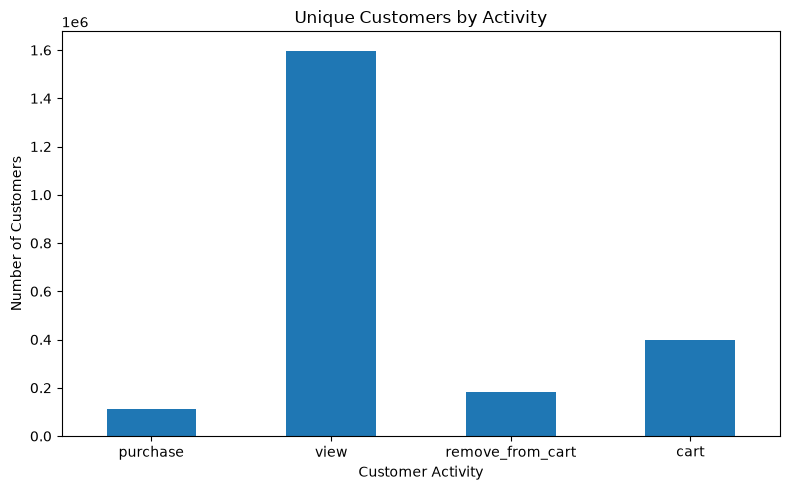

In [6]:
activity_df = activity_df.set_index('event_type')

activity_df['unique_users'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Unique Customers by Activity')
plt.xlabel('Customer Activity')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Retrieving monthly data
query = """
SELECT
    CONVERT(VARCHAR(7), event_time, 120) AS month,
    COUNT(*) AS purchase_events,
    COUNT(DISTINCT user_id) AS unique_buyers,
    SUM(price) AS purchase_value
FROM clean_events
WHERE event_type = 'purchase'
GROUP BY CONVERT(VARCHAR(7), event_time, 120)
ORDER BY month
"""

trend_df = pd.read_sql(query, conn)

trend_df['purchase_value'] = trend_df['purchase_value'].astype(float)

display(trend_df)

C:\Users\ekans\AppData\Local\Temp\ipykernel_17948\4290785618.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  trend_df = pd.read_sql(query, conn)


,month,purchase_events,unique_buyers,purchase_value
0,2019-10,245624,25762,1211538.43
1,2019-11,322417,31524,1531016.90
2,2019-12,213176,25613,1077624.85
3,2020-01,263797,28220,1321535.48
4,2020-02,241993,25759,1206289.21


,month,purchase_events,unique_buyers,purchase_value,growth_pct
0,2019-10,245624,25762,1211538.43,NaN
1,2019-11,322417,31524,1531016.90,26.369652
2,2019-12,213176,25613,1077624.85,-29.613785
3,2020-01,263797,28220,1321535.48,22.634095
4,2020-02,241993,25759,1206289.21,-8.720634


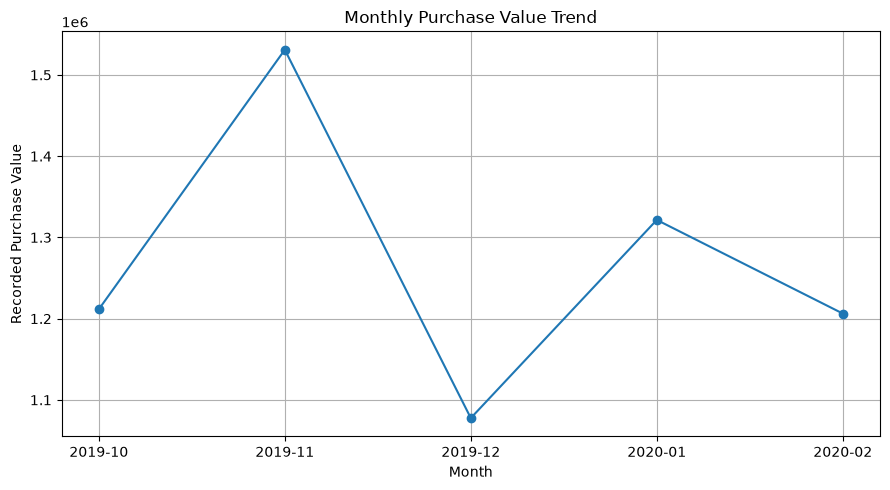

In [8]:
# Calculating month-over-month growth
trend_df['growth_pct'] = trend_df['purchase_value'].pct_change() * 100

display(trend_df)

# Plot monthly purchase value
plt.figure(figsize=(9, 5))

plt.plot(
    trend_df['month'],
    trend_df['purchase_value'],
    marker='o'
)

plt.title('Monthly Purchase Value Trend')
plt.xlabel('Month')
plt.ylabel('Recorded Purchase Value')
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Customer Retention Analysis in Python
query = """
WITH monthly_buyers AS (
    SELECT DISTINCT
        user_id,
        DATEFROMPARTS(YEAR(event_time), MONTH(event_time), 1)
            AS purchase_month
    FROM clean_events
    WHERE event_type = 'purchase'
),

first_purchase AS (
    SELECT
        user_id,
        MIN(purchase_month) AS cohort_month
    FROM monthly_buyers
    GROUP BY user_id
)

SELECT
    f.cohort_month,
    DATEDIFF(MONTH, f.cohort_month, m.purchase_month)
        AS month_number,
    COUNT(*) AS customers
FROM monthly_buyers m
JOIN first_purchase f
    ON m.user_id = f.user_id
GROUP BY
    f.cohort_month,
    DATEDIFF(MONTH, f.cohort_month, m.purchase_month)
ORDER BY f.cohort_month, month_number
"""

cohort_df = pd.read_sql(query, conn)

display(cohort_df)

C:\Users\ekans\AppData\Local\Temp\ipykernel_17948\19873591.py:34: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cohort_df = pd.read_sql(query, conn)


,cohort_month,month_number,customers
0,2019-10-01,0,25762
1,2019-10-01,1,4763
2,2019-10-01,2,3293
3,2019-10-01,3,3399
4,2019-10-01,4,2692
5,2019-11-01,0,26761
6,2019-11-01,1,2618
7,2019-11-01,2,2716
8,2019-11-01,3,2119
9,2019-12-01,0,19702


In [10]:
# Retention Percentage Table
retention = cohort_df.pivot(
    index='cohort_month',
    columns='month_number',
    values='customers'
)

retention_pct = retention.div(retention[0], axis=0) * 100

display(retention_pct.round(2))

month_number,0,1,2,3,4
cohort_month,,,,,
2019-10-01,100.0,18.49,12.78,13.19,10.45
2019-11-01,100.0,9.78,10.15,7.92,NaN
2019-12-01,100.0,8.52,6.46,NaN,NaN
2020-01-01,100.0,8.86,NaN,NaN,NaN
2020-02-01,100.0,NaN,NaN,NaN,NaN


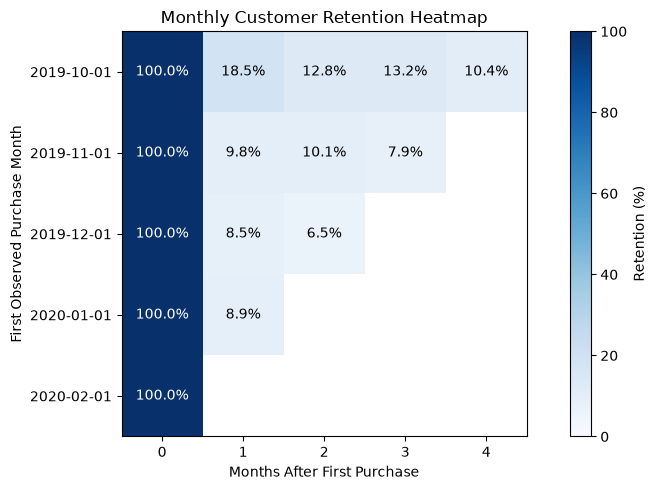

In [11]:
plt.figure(figsize=(9, 5))

plt.imshow(retention_pct, cmap='Blues', vmin=0, vmax=100)

plt.colorbar(label='Retention (%)')

plt.xticks(range(5), retention_pct.columns)
plt.yticks(range(5), retention_pct.index)

for i in range(5):
    for j in range(5):
        value = retention_pct.iloc[i, j]

        if pd.notna(value):
            plt.text(j, i, f'{value:.1f}%',
                     ha='center', va='center',
                     color='white' if value > 50 else 'black')

plt.title('Monthly Customer Retention Heatmap')
plt.xlabel('Months After First Purchase')
plt.ylabel('First Observed Purchase Month')

plt.tight_layout()
plt.show()

In [12]:
# Business Question: Are customers spending more or less per month?
# Average purchase value per buying customer

trend_df['value_per_buyer'] = (
    trend_df['purchase_value'] / trend_df['unique_buyers']
)

display(trend_df[['month', 'unique_buyers', 'value_per_buyer']].round(2))

,month,unique_buyers,value_per_buyer
0,2019-10,25762,47.03
1,2019-11,31524,48.57
2,2019-12,25613,42.07
3,2020-01,28220,46.83
4,2020-02,25759,46.83


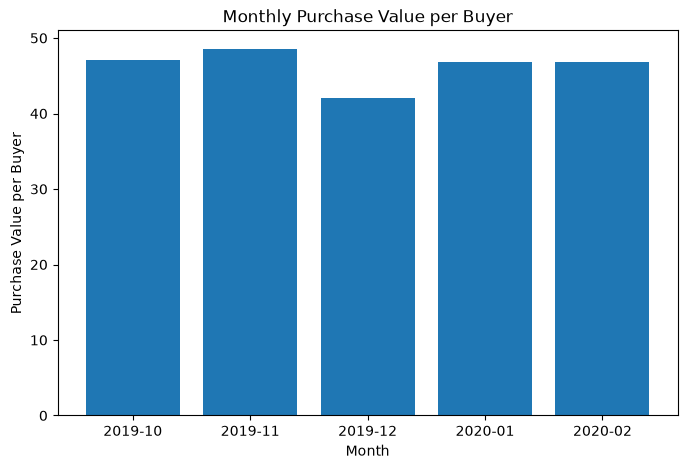

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(trend_df['month'], trend_df['value_per_buyer'])

plt.title('Monthly Purchase Value per Buyer')
plt.xlabel('Month')
plt.ylabel('Purchase Value per Buyer')

plt.show()

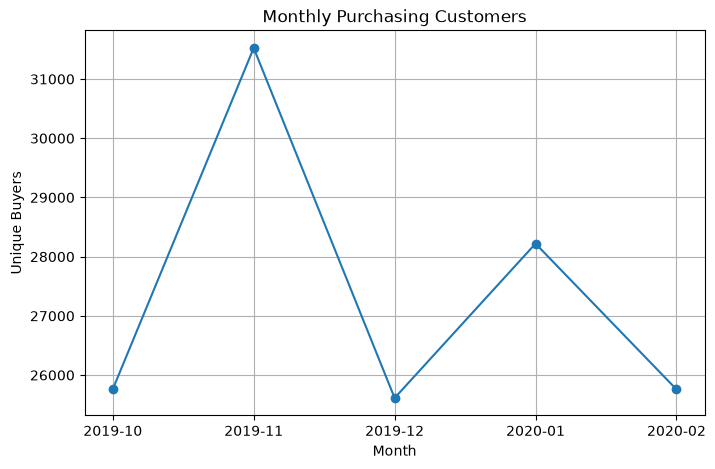

In [14]:
# Business question: Was December's decline also associated with fewer purchasing customers?
plt.figure(figsize=(8, 5))

plt.plot(
    trend_df['month'],
    trend_df['unique_buyers'],
    marker='o'
)

plt.title('Monthly Purchasing Customers')
plt.xlabel('Month')
plt.ylabel('Unique Buyers')

plt.grid(True)
plt.show()

In [15]:
# Business question: Which customer groups represent the largest opportunities for conversion and retention?

segments_df = pd.DataFrame({
    'segment': [
        'Viewed, No Cart/Purchase',
        'Carted, Never Purchased',
        'Purchasing Customers',
        'Other Activity'
    ],
    'customers': [1239279, 288701, 110518, 860]
})

display(segments_df)

,segment,customers
0,"Viewed, No Cart/Purchase",1239279
1,"Carted, Never Purchased",288701
2,Purchasing Customers,110518
3,Other Activity,860


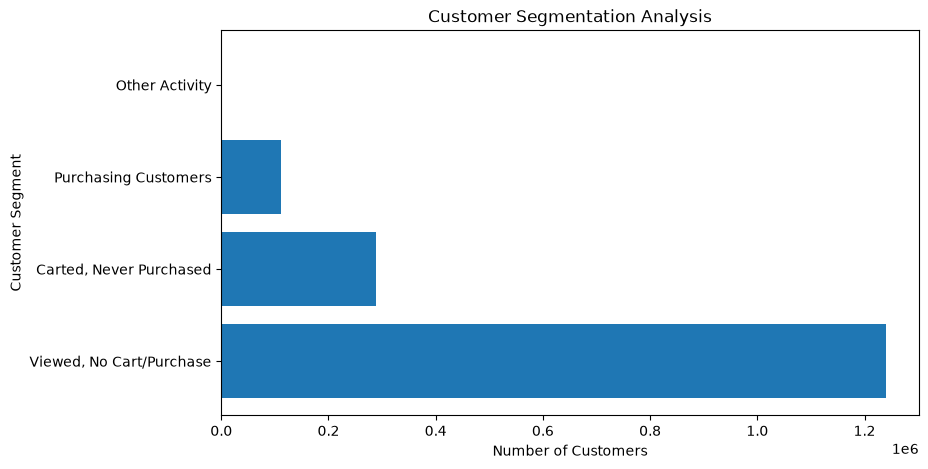

In [16]:
plt.figure(figsize=(9, 5))

plt.barh(segments_df['segment'], segments_df['customers'])

plt.title('Customer Segmentation Analysis')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.show()

In [17]:
# Business question: What percentage of shopping sessions containing cart additions resulted in a recorded purchase?

cart_df = pd.DataFrame({
    'outcome': ['Cart + Purchase', 'Cart Without Purchase'],
    'sessions': [126284, 859529]
})

cart_df['percentage'] = (
    cart_df['sessions'] / cart_df['sessions'].sum() * 100
)

display(cart_df.round(2))

,outcome,sessions,percentage
0,Cart + Purchase,126284,12.81
1,Cart Without Purchase,859529,87.19


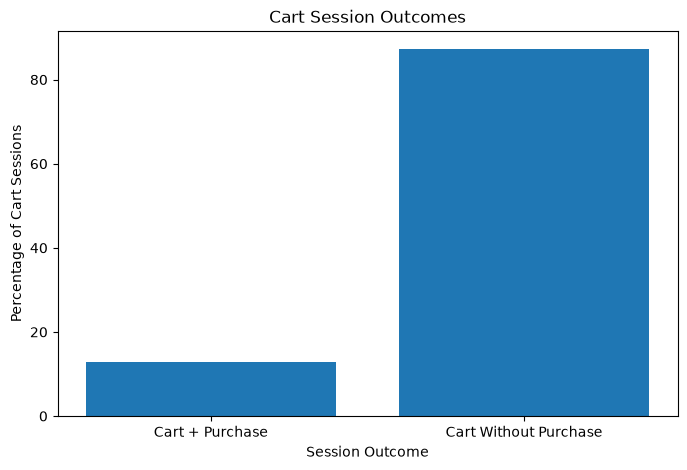

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(cart_df['outcome'], cart_df['percentage'])

plt.title('Cart Session Outcomes')
plt.xlabel('Session Outcome')
plt.ylabel('Percentage of Cart Sessions')

plt.show()

In [19]:
monthly_excel = trend_df[
    ['month', 'purchase_events', 'unique_buyers', 'purchase_value']
]

monthly_excel.to_csv(
    '../05_Excel/Monthly_Performance.csv',
    index=False
)

print("Monthly data exported successfully!")

Monthly data exported successfully!
